# 92103 (Hillcrest) – Building Footprint Analysis

## 1. Fetch building footprints

OSM has no polygon for zip codes, so `src/data/fetch_osm.py` takes the zip boundary from the Census (ZCTA)
and passes it to `ox.features_from_polygon(..., tags={"building": True})`. Run once from the repo root:

```
python src/data/fetch_osm.py --zip 92103
```

Footprints are reprojected to EPSG:32611 (UTM 11N) so all distances and areas are in meters.

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as cx

buildings = gpd.read_parquet("../../data/raw/osm_buildings_92103.parquet")
boundary = gpd.read_parquet("../../data/raw/zcta_92103.parquet")
basemap = cx.providers.Esri.WorldGrayCanvas

print(len(buildings), "buildings |", buildings.crs.to_string())
buildings.head()

7966 buildings | EPSG:32611


,element,id,building,name,addr:housenumber,addr:street,building:levels,geometry
0,relation,5991905,education,NaN,NaN,NaN,NaN,"POLYGON ((483500.988 3624066.966, 483501.188 3..."
1,relation,6795479,yes,NaN,NaN,NaN,NaN,"POLYGON ((484324.314 3624134.705, 484324.272 3..."
2,relation,9438429,yes,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((482332.755 3624223.855, 482335..."
3,relation,15082940,apartments,Eitol Towers,NaN,University Avenue,5,"POLYGON ((486099.892 3623442.678, 486090.012 3..."
4,relation,15394521,apartments,NaN,NaN,NaN,2,"POLYGON ((485548.876 3623282.38, 485548.87 362..."


## 2. Map the original footprints

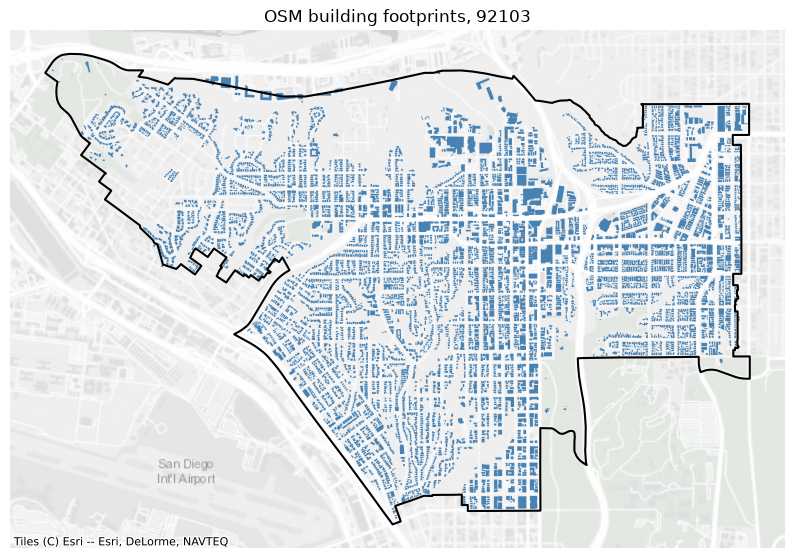

In [2]:
fig, ax = plt.subplots(figsize=(10, 10))
buildings.plot(ax=ax, color="steelblue")
boundary.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1.5)
cx.add_basemap(ax, crs=buildings.crs, source=basemap)
ax.set_title("OSM building footprints, 92103")
ax.set_axis_off()

Zoomed in on University Ave & 5th Ave. This same window is reused in section 4.

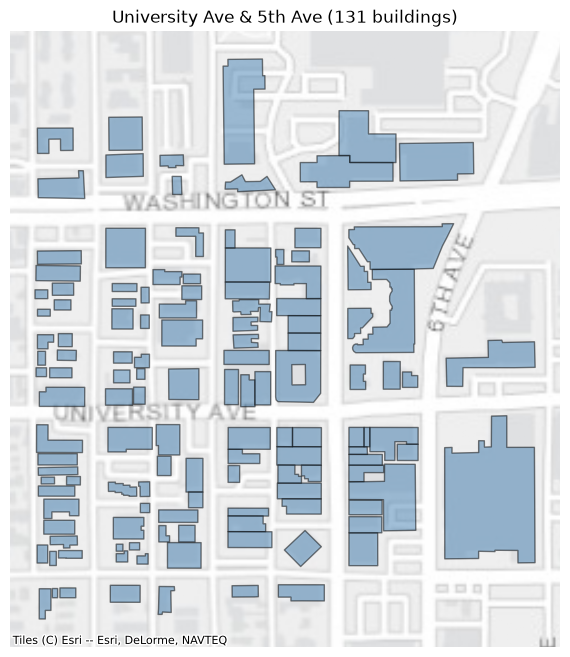

In [3]:
x, y, r = 484900, 3623430, 200  # center (m) and half-width (m)
zoom = buildings.cx[x - r:x + r, y - r:y + r]

fig, ax = plt.subplots(figsize=(8, 8))
zoom.plot(ax=ax, color="steelblue", edgecolor="black", alpha=0.5)
cx.add_basemap(ax, crs=buildings.crs, source=basemap, zoom=16)
ax.set_title(f"University Ave & 5th Ave ({len(zoom)} buildings)")
ax.set_axis_off()

**Observations**
- Most of the zip is well covered. The gaps are mostly canyons and the 163 freeway.
- Buildings line up with the streets on the basemap, so the coordinates look right.
- Some buildings stick out past the top edge of the zip since OSM includes anything touching the boundary.
- A lot of buildings share walls with their neighbors, which will matter later when we buffer them.